In [1]:

from google.colab import files
uploaded = files.upload()


Saving customer_churn_model_v2.csv to customer_churn_model_v2.csv


In [2]:

import pandas as pd
import numpy as np

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nData Types:")
print(df.dtypes)


Dataset Shape: (800, 13)

Column Names:
['CustomerID', 'Age', 'Region', 'TenureMonths', 'SubscriptionType', 'MonthlyChargesINR', 'TotalChargesINR', 'ContractType', 'SupportTickets', 'LatePayments', 'PaymentMethod', 'AutoPay', 'Churn']

First 5 Rows:


,CustomerID,Age,Region,TenureMonths,SubscriptionType,MonthlyChargesINR,TotalChargesINR,ContractType,SupportTickets,LatePayments,PaymentMethod,AutoPay,Churn
0,CUST-100001,57,South,33,Standard,767.25,23893.97,Month-to-Month,4,1,UPI,Yes,Yes
1,CUST-100002,44,South,45,Basic,476.72,21627.46,Two Year,0,1,UPI,Yes,Yes
2,CUST-100003,64,South,57,Basic,414.81,22500.07,One Year,1,1,UPI,No,Yes
3,CUST-100004,57,East,44,Pro,1171.76,50309.16,Month-to-Month,4,0,Card,Yes,Yes
4,CUST-100005,58,North,49,Pro,1130.19,55980.21,Month-to-Month,3,0,Wallet,No,No



Missing Values:
CustomerID           0
Age                  0
Region               0
TenureMonths         0
SubscriptionType     0
MonthlyChargesINR    0
TotalChargesINR      0
ContractType         0
SupportTickets       0
LatePayments         0
PaymentMethod        0
AutoPay              0
Churn                0
dtype: int64

Data Types:
CustomerID            object
Age                    int64
Region                object
TenureMonths           int64
SubscriptionType      object
MonthlyChargesINR    float64
TotalChargesINR      float64
ContractType          object
SupportTickets         int64
LatePayments           int64
PaymentMethod         object
AutoPay               object
Churn                 object
dtype: object


In [3]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    confusion_matrix
)

# Remove customer ID because it is an identifier, not a useful feature
X = df.drop(columns=["CustomerID", "Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

# Identify numeric and categorical columns
numeric_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols = X.select_dtypes(include=["object"]).columns.tolist()

# One-hot encode categories and scale numeric features
preprocessor = ColumnTransformer(
    transformers=[
        ("num", MinMaxScaler(), numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
    ]
)

# Split data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Build and train the Logistic Regression pipeline
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Model training completed successfully!")


Training rows: 640
Testing rows: 160
Model training completed successfully!


In [4]:

# Predict churn labels and probabilities
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("===== MODEL EVALUATION =====")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.3f}")
print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.3f}")
print(f"F1-Score:  {f1_score(y_test, y_pred, zero_division=0):.3f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob):.3f}")

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["No Churn", "Churn"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))


===== MODEL EVALUATION =====
Accuracy:  0.637
Precision: 0.576
Recall:    0.507
F1-Score:  0.540
ROC-AUC:   0.681

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.67      0.73      0.70        93
       Churn       0.58      0.51      0.54        67

    accuracy                           0.64       160
   macro avg       0.62      0.62      0.62       160
weighted avg       0.63      0.64      0.63       160

Confusion Matrix:
[[68 25]
 [33 34]]


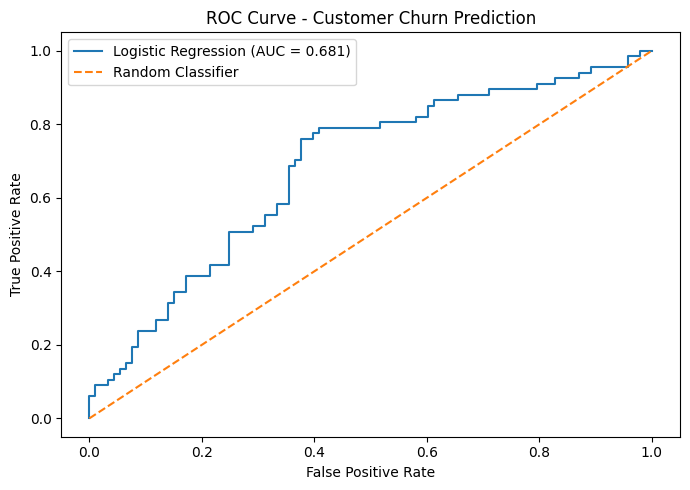

ROC curve saved successfully!


In [5]:

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_value = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc_value:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Customer Churn Prediction")
plt.legend()
plt.tight_layout()
plt.savefig("Churn_ROC_Curve.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("ROC curve saved successfully!")


In [6]:

# Predict churn probability for all 800 customers
all_features = df.drop(columns=["CustomerID", "Churn"])

all_probabilities = model.predict_proba(all_features)[:, 1]

risk_predictions = pd.DataFrame({
    "CustomerID": df["CustomerID"],
    "ActualChurn": df["Churn"],
    "ChurnRiskProbability": all_probabilities.round(4),
    "ChurnRiskPercent": (all_probabilities * 100).round(2)
})

risk_predictions["RiskCategory"] = pd.cut(
    all_probabilities,
    bins=[-0.001, 0.30, 0.60, 1.00],
    labels=["Low", "Medium", "High"]
)

risk_predictions = risk_predictions.sort_values(
    "ChurnRiskProbability", ascending=False
)

risk_predictions.to_csv("Customer_Churn_Risk_Predictions.csv", index=False)

display(risk_predictions.head(10))
print("Total customer predictions:", len(risk_predictions))
print("CSV file created successfully!")


,CustomerID,ActualChurn,ChurnRiskProbability,ChurnRiskPercent,RiskCategory
523,CUST-100524,Yes,0.8290,82.90,High
363,CUST-100364,No,0.8168,81.68,High
423,CUST-100424,Yes,0.8167,81.67,High
381,CUST-100382,Yes,0.8066,80.66,High
34,CUST-100035,Yes,0.8022,80.22,High
316,CUST-100317,No,0.8021,80.21,High
81,CUST-100082,Yes,0.7976,79.76,High
792,CUST-100793,Yes,0.7799,77.99,High
476,CUST-100477,Yes,0.7761,77.61,High
390,CUST-100391,No,0.7757,77.57,High


Total customer predictions: 800
CSV file created successfully!


In [7]:

from google.colab import files

files.download("Customer_Churn_Risk_Predictions.csv")
files.download("Churn_ROC_Curve.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:

readme_content = """
# Predictive Churn Analysis

## Project Overview
This project uses Machine Learning to predict customer churn risk
using a customer churn dataset containing 800 records.

## Objective
Build and evaluate a classification model to identify customers
who may be at risk of leaving a service.

## Dataset
- Total records: 800
- Total columns: 13
- Missing values: 0
- Target variable: Churn

## Technologies Used
- Python
- Pandas
- NumPy
- Scikit-learn
- Matplotlib

## Methodology
1. Data inspection and preprocessing
2. One-Hot Encoding for categorical features
3. MinMax scaling for numerical features
4. 80/20 train-test split
5. Logistic Regression model training
6. Model evaluation using Precision, Recall, F1-score and ROC-AUC
7. Customer churn probability prediction

## Model Evaluation
- Accuracy: 63.7%
- Precision: 57.6%
- Recall: 50.7%
- F1-score: 54.0%
- ROC-AUC: 0.681

These metrics are from the current test split and may vary if the
dataset or model settings change.

## Output Files
- Customer_Churn_Risk_Predictions.csv
- Churn_ROC_Curve.png
- Predictive_Churn_Analysis.ipynb

## Conclusion
The baseline Logistic Regression model provides an initial estimate
of customer churn risk. Further feature engineering and model
comparison may improve performance.

## Author
Student Machine Learning Project
"""

with open("README.md", "w") as f:
    f.write(readme_content)

print("README.md created successfully!")


README.md created successfully!


In [9]:

requirements_content = """pandas
numpy
scikit-learn
matplotlib
"""

with open("requirements.txt", "w") as f:
    f.write(requirements_content)

print("requirements.txt created successfully!")


requirements.txt created successfully!


In [10]:

from google.colab import files

files.download("README.md")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:

files.download("requirements.txt")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>